# Importing

In [185]:
# Dataframe 
import numpy as np 
import pandas as pd 


# String
import string


# Regular Expression
import re


# Split
from sklearn.model_selection import train_test_split


# Pipeline
from sklearn.pipeline import Pipeline


# Model & Vectorization
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer


# Visualization
import matplotlib.pyplot as plt 
import seaborn as sns 
from keras.utils import plot_model
from sklearn import set_config



# Evaluation
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

# Save Model 
import joblib


# Warning 
import warnings
warnings.filterwarnings("ignore")

# Loading

In [186]:
path = r"/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv"
# convert ISO-8859-1 representation to text
data = pd.read_csv(path , encoding='latin1')
df = data.copy()
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# Cleaning

In [187]:
def clean_data(df):

    # Remove columns with all missing values
    df = df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])
    
    # rename v1 col as label , v2 col as text
    df = df.rename(columns={'v1': 'label','v2': 'message_text'})
    
    # Encode labels (0,1)
    df['label'] = df['label'].map({'ham': 0,'spam': 1})

    return df

In [188]:
df = clean_data(df) 
print(f"Before Cleaning : \n\n{data.head()}")
print(f"\n{'*'*70}\nAfter Cleaning : \n\n{df.head()}")

Before Cleaning : 

     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

**********************************************************************
After Cleaning : 

   label                                       message_text
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then s

# Exploratory Analysis

In [189]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())




# Distribution of ham and spam
counts = df['label'].value_counts()

print("\nMessage distribution:")
print(f"Ham: {counts[0]}")
print(f"Spam: {counts[1]}")

# Percentage of ham and spam
percentages = df['label'].value_counts(normalize=True) * 100

print("\nMessage percentage:")
print(f"Ham: {percentages[0]:.2f}%")
print(f"Spam: {percentages[1]:.2f}%")





# Calculate message length
df['message_length'] = df['message_text'].str.len()

# Average character length
avg_length = df.groupby('label')['message_length'].mean()
df = df.drop(columns=['message_length'])


print("\nAverage message length:")
print(f"Ham: {avg_length[0]:.2f}")
print(f"Spam: {avg_length[1]:.2f}")

Missing values:
label           0
message_text    0
dtype: int64

Message distribution:
Ham: 4825
Spam: 747

Message percentage:
Ham: 86.59%
Spam: 13.41%

Average message length:
Ham: 71.02
Spam: 138.87


# Setup

In [190]:
SEED = 42
alpha = 0.12

# Split the dataset

In [191]:
X = df['message_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=SEED,stratify=df['label'])

# TF-IDF & Naive Bayes Pipeline

In [192]:
nb_pipeline = Pipeline([

    
    ('tfidf', TfidfVectorizer(lowercase=True,stop_words='english')),
    
    ('nb', MultinomialNB(alpha = alpha))
    
])


# Train

In [193]:
# Fit pipeline on train only to prevent data leakage
nb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(stop_words='english')),
                ('nb', MultinomialNB(alpha=0.12))])

# Test

In [194]:
# Predict directly from test text
y_pred = nb_pipeline.predict(X_test)


# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.9865


# Evaluation

In [195]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test,y_pred,target_names=["Ham", "Spam"]))


Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.99      0.91      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115



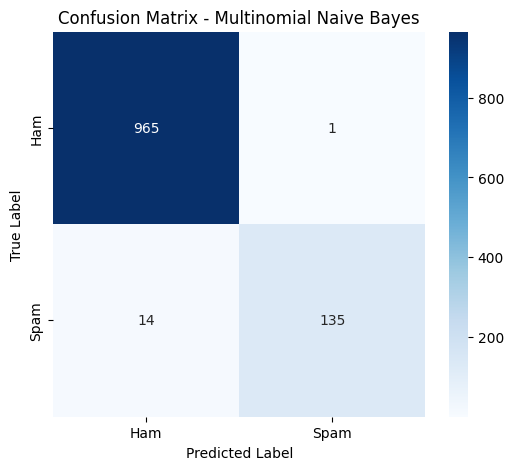

In [196]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=["Ham", "Spam"],yticklabels=["Ham", "Spam"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Multinomial Naive Bayes")

plt.show()

# Real-world example messages

# Model Explanation

In [197]:
# Get the model and TF-IDF
tfidf = nb_pipeline.named_steps['tfidf']
nb = nb_pipeline.named_steps['nb']

# Get all words in the data
words = tfidf.get_feature_names_out()

In [198]:
def explain(message):

    # Predict: 0 = HAM, 1 = SPAM
    prediction = nb_pipeline.predict([message])[0]

    
    # Find words in the message
    message_words = set(message.lower().split())

    
    # Compare each word between SPAM and HAM
    spam_scores = (nb.feature_log_prob_[1] - nb.feature_log_prob_[0])

    
    # Sort words from most SPAM-related
    spam_words = words[spam_scores.argsort()[::-1]]

    
    # Find SPAM-related words in the message
    reasons = [word for word in spam_words if word in message_words and word.isalpha()][:5]


    
    print(f"Message: {message}\n")
    print(f"Prediction: {'SPAM' if prediction == 1 else 'HAM'}")

    if reasons:
         print(f"\nWhy: {', '.join(reasons)}")
    else:
         print("\nWhy: No strong spam words found")

    print("-" * 50)

In [199]:
test_messages = [
    "Hey, are we still meeting for lunch today?",
    "Congratulations! You have won a $1,000 gift card. Call now to claim."
]

for message in test_messages:
    explain(message)

Message: Hey, are we still meeting for lunch today?

Prediction: HAM

Why: lunch, meeting
--------------------------------------------------
Message: Congratulations! You have won a $1,000 gift card. Call now to claim.

Prediction: SPAM

Why: won, gift
--------------------------------------------------


# Save Model

In [200]:
joblib.dump(nb_pipeline, "spam_classifier_pipeline.pkl")

['spam_classifier_pipeline.pkl']

In [201]:
test_message = [
    """Subject: URGENT: Unusual sign-in activity detected on your account
Dear Customer,

We noticed a login attempt to your account from an unrecognized device in a different location 
(IP Address: 192.168.1.50, Lagos, Nigeria).

If this was not you, your account has been temporarily locked for your protection. 
You must verify your identity within 24 hours or your account will be permanently suspended.

Click here to secure your account

Thank you,
Security Operations Team"""
]

prediction = nb_pipeline.predict(test_message)

explain(test_message[0])

Message: Subject: URGENT: Unusual sign-in activity detected on your account
Dear Customer,

We noticed a login attempt to your account from an unrecognized device in a different location 
(IP Address: 192.168.1.50, Lagos, Nigeria).

If this was not you, your account has been temporarily locked for your protection. 
You must verify your identity within 24 hours or your account will be permanently suspended.

Click here to secure your account

Thank you,
Security Operations Team

Prediction: SPAM

Why: verify, attempt, click, team, account
--------------------------------------------------
